# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [28]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [29]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [30]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [31]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [32]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [33]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [34]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 2
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 02 | Semilla: 1002
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: e0c1f82a88ea


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [35]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [36]:
from sklearn.base import clone

filas = {}
for cw in [None, 'balanced']:
    m = make_pipeline(clone(preprocesamiento),
                      LogisticRegression(class_weight=cw, max_iter=1000, random_state=semilla))
    m.fit(X_train, y_train)
    p = m.predict(X_valid)
    filas[str(cw)] = {
        'accuracy': accuracy_score(y_valid, p),
        'precision': precision_score(y_valid, p, zero_division=0),
        'recall': recall_score(y_valid, p, zero_division=0),
        'f1': f1_score(y_valid, p, zero_division=0),
        'tardios_predichos': int(p.sum()),
    }
filas['referencia (Dummy)'] = {
    'accuracy': accuracy_score(y_valid, pred_ref),
    'precision': precision_score(y_valid, pred_ref, zero_division=0),
    'recall': recall_score(y_valid, pred_ref, zero_division=0),
    'f1': f1_score(y_valid, pred_ref, zero_division=0),
    'tardios_predichos': int(pred_ref.sum()),
}
pd.DataFrame(filas).T.round(3)

,accuracy,precision,recall,f1,tardios_predichos
None,0.932,0.333,0.003,0.006,3.0
balanced,0.654,0.119,0.645,0.201,1918.0
referencia (Dummy),0.932,0.000,0.000,0.000,0.0


In [37]:
# TODO 1. Entrene el modelo y genere predicciones.
from sklearn.base import clone

peso_clases = 'balanced'

modelo = make_pipeline(
    clone(preprocesamiento),
    LogisticRegression(class_weight=peso_clases, max_iter=1000, random_state=semilla)
)
modelo.fit(X_train, y_train)
pred = modelo.predict(X_valid)

In [38]:
m_none = make_pipeline(clone(preprocesamiento),
                       LogisticRegression(class_weight=None, max_iter=1000, random_state=semilla)).fit(X_train, y_train)
_, fp_n, fn_n, tp_n = confusion_matrix(y_valid, m_none.predict(X_valid)).ravel()
print(f'None -> FP={fp_n}, FN={fn_n}, TP={tp_n}, costo=R$ {8*fp_n + 35*fn_n:,.0f}')

None -> FP=2, FN=354, TP=1, costo=R$ 12,406


### Actividad 1. Explicación de elección en la sección de interpretación.
La elección en este caso fue la de **balanced** debido a que **None** hace que el modelo en este escenario, el modelo, casi nunca prediga "tardío" y se comporte como la referencia del ejercicio. Hay que tener en cuenta que **None** tiene un costo ligeramente menor, R 12.406 frente a R 17.914, además de tener mayor **accuracy**. En el caso del costo menor, se debe a que este no interviene en ningún pedido. Ahora Balanced detecta el 64,5% de los pedidos tardíos; sin embargo, presenta muchas falsas alarmas, precisión del 0,119 respectivamente. Con el umbral de 0,5, todavía no permite compensar económicamente. Pendiente de las mejoras de las próximas semanas.

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [39]:
# TODO 2. Calcule las métricas y muestre la matriz de confusión.
proba = modelo.predict_proba(X_valid)[:, 1]
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred, zero_division=0),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),
    'ap': average_precision_score(y_valid, proba),
}
print(pd.Series(medidas).round(4))
print('Prevalencia de tardíos en validación:', round(y_valid.mean(), 4))

matriz = pd.DataFrame(confusion_matrix(y_valid, pred),
                      index=['real: a tiempo', 'real: tardío'],
                      columns=['pred: a tiempo', 'pred: tardío'])
display(matriz)

accuracy     0.6543
precision    0.1194
recall       0.6451
f1           0.2015
roc_auc      0.7036
ap           0.1527
dtype: float64
Prevalencia de tardíos en validación: 0.0676


,pred: a tiempo,pred: tardío
real: a tiempo,3206,1689
real: tardío,126,229


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [40]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.
analisis['fp'] = ((analisis['is_late'] == 0) & (analisis['pred'] == 1)).astype(int)
analisis['fn'] = ((analisis['is_late'] == 1) & (analisis['pred'] == 0)).astype(int)

def tabla_segmento(columna):
    t = analisis.groupby(columna).agg(
        pedidos=('error', 'size'),
        tardios_reales=('is_late', 'sum'),
        errores=('error', 'sum'),
        falsos_positivos=('fp', 'sum'),
        falsos_negativos=('fn', 'sum'),
    )
    t['tasa_error_%'] = (100 * t['errores'] / t['pedidos']).round(2)
    return t

por_mes = tabla_segmento('mes_compra').sort_index()
por_estado = tabla_segmento('customer_state')

print('Por mes de compra')
display(por_mes)
print('Por estado del cliente (estados con al menos 50 pedidos, de mayor a menor error)')
display(por_estado[por_estado['pedidos'] >= 50].sort_values('tasa_error_%', ascending=False))

Por mes de compra


,pedidos,tardios_reales,errores,falsos_positivos,falsos_negativos,tasa_error_%
mes_compra,,,,,,
1,384,25,123,111,12,32.03
2,427,50,130,114,16,30.44
3,552,82,210,193,17,38.04
4,512,25,164,155,9,32.03
5,584,18,216,211,5,36.99
6,490,10,140,134,6,28.57
7,584,22,238,229,9,40.75
8,560,33,254,239,15,45.36
9,229,7,91,88,3,39.74


Por estado del cliente (estados con al menos 50 pedidos, de mayor a menor error)


,pedidos,tardios_reales,errores,falsos_positivos,falsos_negativos,tasa_error_%
customer_state,,,,,,
CE,76,9,56,56,0,73.68
PA,53,8,38,38,0,71.70
BA,203,22,135,132,3,66.50
ES,117,8,73,72,1,62.39
MT,50,5,31,28,3,62.00
SC,194,13,120,116,4,61.86
RJ,631,80,390,381,9,61.81
PE,86,8,50,46,4,58.14
GO,107,5,41,39,2,38.32


### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [41]:
# TODO 4. Calcule el costo total con la matriz de confusión.
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
costo_fp_fn = float(8 * fp + 35 * fn)

print(f'FP = {fp} | FN = {fn}')
print(f'Costo del modelo: R$ {costo_fp_fn:,.0f}')

# Comparación con no intervenir nunca (el Dummy marca todo como a tiempo)
_, fp_ref, fn_ref, _ = confusion_matrix(y_valid, pred_ref).ravel()
print(f'Costo de la referencia: R$ {8 * fp_ref + 35 * fn_ref:,.0f}')

FP = 1689 | FN = 126
Costo del modelo: R$ 17,922
Costo de la referencia: R$ 12,425


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [42]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [43]:
from sklearn.base import clone

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.1 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

**Respuesta:**
El modelo de referencia tiene un **Accuracy** alto de 0,932, únicamente porque el 93 % de los pedidos llega a tiempo; no detecta ningún retraso **Recall** 0 y F1 0. Debido a esto el **Accuracy** no es un buen criterio. Con `class_weight=None`, la regresión logística se comporta casi igual que la referencia, para corroborarlo este solo marcó 3 pedidos como tardíos, acertó 1 y detectó 1 de 355 tardíos **Recall** 0,003, F1 0,006. Su costo R 12.406 es ligeramente menor que el de **balanced** R 17.914 únicamente porque casi no interviene en ningún pedido. En este caso se eligió `class_weight='balanced'` debido a que es la única opción que cumple el objetivo de anticipar las entregas tardías, pues este detecta el 64,5 % de los pedidos tardíos (229 de 355) y su F1 sube a 0,202. El precio es una Precision baja (0,119) y un **Accuracy** menor (0,654), porque genera muchas falsas alarmas (1.688). Con el umbral de decisión de 0,5 su costo R 17.914 todavía supera al de no intervenir R 12.425.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

**Respuesta:**
El mayor error aparece en pedidos de ciertos meses y estados, y casi siempre es una falsa alarma. Por mes de compra, los de mayor tasa de error son agosto 45,4 %, 560 pedidos, julio 40,8 %, 584 y septiembre 39,7 %, 229; el menor es diciembre 14,1 %, 284. Por estado del cliente con al menos 50 pedidos, los de mayor error son CE 73,7 %, 76 pedidos, PA 71,7 %, 53, BA 66,5 %, 203 y RJ 61,8 %, 631, frente a SP 20,0 %, 2.210 pedidos y MG 19,7 %, 569. CE, PA y MT tienen pocos pedidos, así que sus tasas son menos confiables. El tipo de error dominante es el falso positivo: 1.688 de los 1.814 errores 93 %. En RJ, por ejemplo, hay 381 falsos positivos y solo 9 falsos negativos.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

**Respuesta:**
Para la semana 13 es impricendible mejorar la información de ubicación, que es donde se concentra el error. Hoy `customer_state` y `estado_vendedor` entran por separado con One-Hot, y un modelo lineal no puede capturar el efecto de la ruta entre ambos.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [44]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_02.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Semana 14 - PCA y evaluación de mejoras al modelo**

Predicción de entregas tardías en Olist: reducción de dimensionalidad, regularización y contrastes estadísticos.

## Actividad 1
Generar la curva de varianza explicada acumulada, registrar el número de componentes y explicar su utilidad para el problema.

Variables numéricas iniciales: 24
Componentes que explican >= 90 %: 15 (varianza acumulada = 0.9053)
Reducción: de 24 variables a 15 componentes (37.5 % menos dimensiones)


,componente,varianza_explicada,varianza_acumulada
0,1,0.1908,0.1908
1,2,0.0961,0.2869
2,3,0.0784,0.3653
3,4,0.0738,0.4391
4,5,0.0727,0.5118
5,6,0.0505,0.5623
6,7,0.0427,0.6050
7,8,0.0422,0.6472
8,9,0.0416,0.6887
9,10,0.0415,0.7302


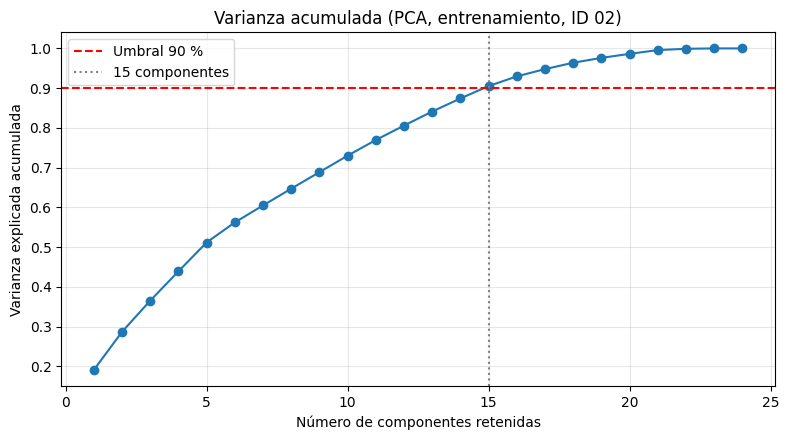

CP1 -> variables con mayor peso absoluto:
valor_pagado         0.407
valor_productos      0.390
precio_maximo        0.358
peso_total_g         0.352
volumen_total_cm3    0.326
Name: CP1, dtype: float64

CP2 -> variables con mayor peso absoluto:
proporcion_flete      0.364
precio_maximo        -0.354
cantidad_items        0.353
cantidad_productos    0.322
valor_flete           0.288
Name: CP2, dtype: float64

CP3 -> variables con mayor peso absoluto:
vendedor_mismo_estado    0.514
dias_prometidos         -0.496
vendedor_misma_ciudad    0.361
dia_semana_compra       -0.333
compra_fin_semana       -0.326
Name: CP3, dtype: float64



In [45]:
# Actividad 1. PCA solo sobre las variables numéricas, ajustado SOLO con entrenamiento.

imputador_num = SimpleImputer(strategy='median')
escalador = StandardScaler()

Xtr_num = escalador.fit_transform(imputador_num.fit_transform(train[columnas_numericas]))

pca_completo = PCA(svd_solver='full')  # todas las componentes, para ver la curva
pca_completo.fit(Xtr_num)

var_ratio = pca_completo.explained_variance_ratio_
var_acum = np.cumsum(var_ratio)
UMBRAL = 0.90
n_comp_90 = int(np.argmax(var_acum >= UMBRAL) + 1)  # mínimo de componentes con >= 90 %

n_vars_num = len(columnas_numericas)
print('Variables numéricas iniciales:', n_vars_num)
print('Componentes que explican >= 90 %:', n_comp_90,
      f'(varianza acumulada = {var_acum[n_comp_90 - 1]:.4f})')
print(f'Reducción: de {n_vars_num} variables a {n_comp_90} componentes '
      f'({100 * (1 - n_comp_90 / n_vars_num):.1f} % menos dimensiones)')

tabla_var = pd.DataFrame({
    'componente': np.arange(1, n_vars_num + 1),
    'varianza_explicada': var_ratio.round(4),
    'varianza_acumulada': var_acum.round(4),
})
display(tabla_var.head(n_comp_90 + 2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, n_vars_num + 1), var_acum, marker='o')
ax.axhline(UMBRAL, color='red', linestyle='--', label='Umbral 90 %')
ax.axvline(n_comp_90, color='gray', linestyle=':', label=f'{n_comp_90} componentes')
ax.set_xlabel('Número de componentes retenidas')
ax.set_ylabel('Varianza explicada acumulada')
ax.set_title(f'Varianza acumulada (PCA, entrenamiento, ID {identificador})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
Path('reports').mkdir(exist_ok=True)
plt.savefig(f'reports/S14_varianza_acumulada_ID_{identificador}.png', dpi=150)
plt.show()

# Qué variables pesan más en las primeras componentes (para explicar qué se resume).
pesos = pd.DataFrame(pca_completo.components_[:3].T,
                     index=columnas_numericas, columns=['CP1', 'CP2', 'CP3'])
for cp in ['CP1', 'CP2', 'CP3']:
    print(cp, '-> variables con mayor peso absoluto:')
    print(pesos[cp].reindex(pesos[cp].abs().sort_values(ascending=False).index).head(5).round(3))
    print()

##Interpretación de los Resultados
Para esta primera actividad se utilizaron 24 variables iniciales, en las cuales se conservaron 15 componentes que de cierta manera explican el 90,53% de la varianza acumulada. Estos componentes reducen aproximadamente el 37,5% de las dimensiones numéricas; las 4 categóricas (One-Hot) aportan 126 columnas, de modo que el modelo recibe 150 columnas sin PCA y 141 con PCA. Por otro lado, la curva es gradual: la CP1 explica solo 19,1 % y hacen falta 15 de 24 componentes, así que la redundancia entre variables se modera. La mayor parte de la información compartida está en el bloque de tamaño y valor del pedido, es decir, la CP1 pesa sobre todo en: valor_pagado, valor_productos, precio_maximo, peso_total_g y volumen_total_cm3. PCA resume ese bloque en pocas direcciones y reduce la colinealidad, lo que podría estabilizar los coeficientes de la regresión logística. Se descarta el 9,47 % restante de la varianza, y PCA ordena por variabilidad, no por capacidad de distinguir entregas tardías. Además, los componentes mezclan variables y son más difíciles de interpretar que dias_prometidos o valor_flete por separado. Si PCA ayuda o no al modelo, solo se sabe comparando B con A.

## Actividad 2
Comparar las cuatro configuraciones con las métricas indicadas y presentar una conclusión que contraste el modelo sin PCA con los modelos que utilizan PCA.

In [46]:
def construir_preprocesamiento(usar_pca):
    """Misma preparación en A-D. Solo cambia si las numéricas pasan por PCA."""
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=UMBRAL, svd_solver='full'))
    return ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas)
    ])

experimentos = {
    'A. Referencia (sin PCA, C=1.0)':        dict(pca=False, C=1.0),
    'B. PCA 90 %, C=1.0':                    dict(pca=True,  C=1.0),
    'C. PCA 90 %, C=0.1 (más penalización)': dict(pca=True,  C=0.1),
    'D. PCA 90 %, C=10.0 (menos penalización)': dict(pca=True, C=10.0),
}
UMBRAL_CLASIF = 0.50
COSTO_FP, COSTO_FN = 8, 35

In [47]:
resultados = {}
modelos = {}
for nombre, cfg in experimentos.items():
    m = make_pipeline(
        construir_preprocesamiento(cfg['pca']),
        LogisticRegression(C=cfg['C'], class_weight='balanced',
                           max_iter=1000, random_state=semilla)
    )
    m.fit(X_train, y_train)                          # todo se ajusta con entrenamiento
    proba_v = m.predict_proba(X_valid)[:, 1]
    pred_v = (proba_v >= UMBRAL_CLASIF).astype(int)  # mismo umbral 0,50 en los cuatro
    tn, fp, fn, tp = confusion_matrix(y_valid, pred_v).ravel()
    resultados[nombre] = {
        'accuracy': accuracy_score(y_valid, pred_v),
        'precision': precision_score(y_valid, pred_v, zero_division=0),
        'recall': recall_score(y_valid, pred_v, zero_division=0),
        'f1': f1_score(y_valid, pred_v, zero_division=0),
        'ap': average_precision_score(y_valid, proba_v),
        'roc_auc': roc_auc_score(y_valid, proba_v),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'costo_brl': float(COSTO_FP * fp + COSTO_FN * fn),
    }
    modelos[nombre] = m

tabla = pd.DataFrame(resultados).T
tabla['n_componentes_pca'] = [
    modelos[n].named_steps['columntransformer'].named_transformers_['numericas'][-1].n_components_
    if experimentos[n]['pca'] else np.nan for n in tabla.index]
cols_metricas = ['accuracy', 'precision', 'recall', 'f1', 'ap', 'roc_auc']
tabla['n_columnas_clasificador'] = [
    modelos[n][:-1].transform(X_valid).shape[1] for n in tabla.index]
tabla[cols_metricas] = tabla[cols_metricas].astype(float).round(4)
tabla

,accuracy,precision,recall,f1,ap,roc_auc,TN,FP,FN,TP,costo_brl,n_componentes_pca,n_columnas_clasificador
"A. Referencia (sin PCA, C=1.0)",0.6543,0.1194,0.6451,0.2015,0.1527,0.7036,3206.0,1689.0,126.0,229.0,17922.0,NaN,150
"B. PCA 90 %, C=1.0",0.6486,0.1116,0.6028,0.1883,0.1349,0.6742,3191.0,1704.0,141.0,214.0,18567.0,15.0,141
"C. PCA 90 %, C=0.1 (más penalización)",0.6472,0.1124,0.6113,0.1899,0.1363,0.6734,3181.0,1714.0,138.0,217.0,18542.0,15.0,141
"D. PCA 90 %, C=10.0 (menos penalización)",0.6478,0.1109,0.6000,0.1873,0.1334,0.6743,3188.0,1707.0,142.0,213.0,18626.0,15.0,141


##Interpretación de los Resultados
- **B frente a A**: PCA empeoró todas las métricas de ranking y detección. Recall bajó de 0,6451 a 0,6028, AP de 0,1527 a 0,1349 y ROC-AUC de 0,7036 a 0,6742. Ademas se dejaron de detectar 15 pedidos tardíos más (FN 126 → 141) y hubo 15 falsas alarmas más. La Accuracy casi no cambió (0,6543 → 0,6486).
- **C y D frente a B**: C=0,1 mejora levemente (Recall 0,611, FN 138); C=10 empeora levemente (Recall 0,600, FN 142). Las diferencias son de 4 a 5 pedidos tardíos.
- Ninguna configuración con PCA alcanza a A: la mejor de ellas (C) sigue con 12 FN más.

**Supuestos y limitaciones:** No se aplicó ninguna prueba estadística de comparación de modelos, así que las diferencias entre B, C y D (unas pocas unidades) no son concluyentes. La diferencia entre A y los modelos con PCA es mayor y consistente en cinco métricas, pero tampoco se demostró significancia estadística.

**Conclusión sobre PCA:** en esta muestra, reducir variables no mejoró la predicción. Es un resultado válido y debe quedar registrado en la bitácora.

## Actividad 3
Calcular falsos positivos, falsos negativos y costo didáctico. Elegir un modelo y justificar la decisión empresarial.

,FP,FN,TP,recall,precision,costo_brl,ahorro_vs_no_intervenir_brl
"A. Referencia (sin PCA, C=1.0)",1689.0,126.0,229.0,0.6451,0.1194,17922.0,-5497.0
"B. PCA 90 %, C=1.0",1704.0,141.0,214.0,0.6028,0.1116,18567.0,-6142.0
"C. PCA 90 %, C=0.1 (más penalización)",1714.0,138.0,217.0,0.6113,0.1124,18542.0,-6117.0
"D. PCA 90 %, C=10.0 (menos penalización)",1707.0,142.0,213.0,0.6000,0.1109,18626.0,-6201.0


Costo de no intervenir nunca: R$ 12,425 (FN = 355)
Menor costo   -> A. Referencia (sin PCA, C=1.0)
Mayor F1      -> A. Referencia (sin PCA, C=1.0)
Mayor Recall  -> A. Referencia (sin PCA, C=1.0)


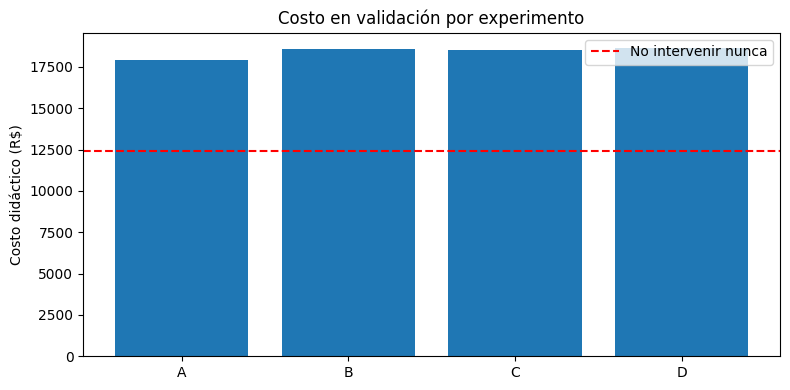

In [48]:
# Actividad 3. FP, FN y costo didáctico (R$ 8 por FP, R$ 35 por FN).
# Referencia de "no intervenir nunca" (todo a tiempo): todos los tardíos son FN.
fn_nada = int(y_valid.sum())
costo_nada = float(COSTO_FN * fn_nada)

tabla_costos = tabla[['FP', 'FN', 'TP', 'recall', 'precision', 'costo_brl']].copy()
tabla_costos['ahorro_vs_no_intervenir_brl'] = costo_nada - tabla_costos['costo_brl']
display(tabla_costos)
print(f'Costo de no intervenir nunca: R$ {costo_nada:,.0f} (FN = {fn_nada})')

mejor_costo = tabla_costos['costo_brl'].idxmin()
mejor_f1 = tabla['f1'].astype(float).idxmax()
mejor_recall = tabla['recall'].astype(float).idxmax()
print('Menor costo   ->', mejor_costo)
print('Mayor F1      ->', mejor_f1)
print('Mayor Recall  ->', mejor_recall)

fig, ax = plt.subplots(figsize=(8, 4))
etiquetas = [n.split('.')[0] for n in tabla_costos.index]
ax.bar(etiquetas, tabla_costos['costo_brl'])
ax.axhline(costo_nada, color='red', linestyle='--', label='No intervenir nunca')
ax.set_ylabel('Costo didáctico (R$)')
ax.set_title('Costo en validación por experimento')
ax.legend()
plt.tight_layout()
plt.savefig(f'reports/S14_costos_ID_{identificador}.png', dpi=150)
plt.show()

##Interpretación de los resultados

**Costos:**
* A = 8·1.689 + 35·126 = R 17.922*
* B= R 18.567
* C = R 18.542
* D= R  18.626
* No intervenir nunca cuesta 35·355 = R$ 12.425.

**Modelo elegido:**
El modelo elegido fue el A (sin PCA, C=1,0), ya que responde la pregunta de análisis sin conflicto: en esta muestra A es a la vez el de más aciertos (Accuracy 0,654), el que identifica más entregas tardías (Recall 0,6451, 229 de 355) y el de menor costo. Frente a B, A ahorra R 645 en validación y frente al mejor modelo con PCA (C) ahorra R 620. Además, es el más simple. Sin embargo, aunque A se presente como "estadísticamente superior", la validación es una sola y el costo ignora el costo fijo de operar un sistema de alertas.No se puede afirmar entonces que A sea superior, ademas A (R 17.922) cuesta R 5.497 más que no intervenir nunca (R$ 12.425).

## Actividad 4
Aplicar KS sobre valor_flete, formular las hipótesis e interpretar los resultados con una limitación metodológica.

* H0: valor_flete tiene la misma distribución * en entrenamiento y en validación.
* H1: las distribuciones de valor_flete en ambos conjuntos son diferentes.
* Nivel de significancia: α = 0,05.

n entrenamiento = 24500 | n validación = 5250
Estadístico D = 0.0116
Valor p       = 0.6054
Decisión (alpha = 0.05): No rechazar H0


,entrenamiento,validación
count,24500.000,5250.000
mean,22.721,22.938
std,23.062,22.433
min,0.000,0.000
25%,13.890,13.820
50%,17.170,17.190
75%,23.850,23.775
max,1794.960,347.240
mediana,17.170,17.190


Proporción de valores distintos en entrenamiento: 0.188 (mientras más baja, más empates)


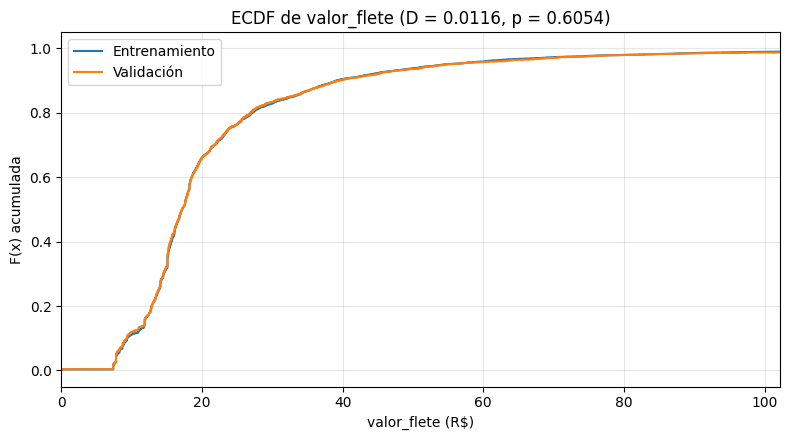

In [49]:
# Actividad 4. Kolmogorov-Smirnov: valor_flete entre entrenamiento y validación.
# H0: valor_flete tiene la misma distribución en entrenamiento y validación.
# H1: las distribuciones son diferentes.  alpha = 0,05
a = train['valor_flete'].dropna()
b = valid['valor_flete'].dropna()
ALFA = 0.05

res_ks = ks_2samp(a, b, alternative='two-sided')
D, p = float(res_ks.statistic), float(res_ks.pvalue)
decision = 'Rechazar H0' if p < ALFA else 'No rechazar H0'

print(f'n entrenamiento = {len(a)} | n validación = {len(b)}')
print(f'Estadístico D = {D:.4f}')
print(f'Valor p       = {p:.4f}')
print(f'Decisión (alpha = {ALFA}): {decision}')

desc = pd.DataFrame({'entrenamiento': a.describe(), 'validación': b.describe()}).round(3)
desc.loc['mediana'] = [a.median(), b.median()]
display(desc)

# Limitación: empates (valores repetidos por redondeo a centavos / fletes idénticos)
prop_unicos = a.nunique() / len(a)
print(f'Proporción de valores distintos en entrenamiento: {prop_unicos:.3f} '
      f'(mientras más baja, más empates)')

fig, ax = plt.subplots(figsize=(8, 4.5))
for serie, etiqueta in [(a, 'Entrenamiento'), (b, 'Validación')]:
    x = np.sort(serie.values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', label=etiqueta)
ax.set_xlim(0, a.quantile(0.99))
ax.set_xlabel('valor_flete (R$)')
ax.set_ylabel('F(x) acumulada')
ax.set_title(f'ECDF de valor_flete (D = {D:.4f}, p = {p:.4f})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'reports/S14_ks_ecdf_ID_{identificador}.png', dpi=150)
plt.show()

##Interpretación de los resultados
Hipótesis:
* H0: valor_flete tiene la misma distribución en entrenamiento y validación.
* H1: las distribuciones difieren. α = 0,05.

**Resultado:** D = 0,0116 y valor p = 0,6054, con n = 24.500 (entrenamiento) y n = 5.250 (validación). Como p ≥ 0,05, no se rechaza H0: no hay evidencia suficiente de que la distribución de valor_flete difiera entre ambas particiones. Las medianas son casi idénticas (17,17 y 17,19) y las curvas ECDF prácticamente se superponen.Esto no demuestra que las distribuciones sean idénticas ni que el modelo esté validado, y no compara el desempeño de A, B, C o D.

Limitación metodológica: la prueba KS clásica supone distribuciones continuas, pero valor_flete tiene muchos valores repetidos (solo ~18,8 % de valores distintos en entrenamiento, por redondeo a centavos y fletes iguales). Con tantos empates el valor p es aproximado y debe leerse con cautela. Además se revisó una sola variable; que valor_flete se parezca no garantiza que las otras 27 variables o la tasa de retrasos se comporten igual.

##Analisis Final
En base a los resultados obtenidos, decir que el criterio del costo es el más sensato, ya que se ponderan los errores que presenta y su costo para la empresa (FN a R$ 35 y FP a R$ 8) y entrega una variable comparable.

Evidencia:

| Modelo| Accuracy | Recall | Costo (R$) |
|---|---|---|---|
|A| 0,654 | 0,645 | 17.922 |
|B| 0,649 | 0,603 | 18.567 |
|C| 0,647 | 0,611 | 18.542 |
|D| 0,648 | 0,600 | 18.626 |

Por otro lado, si se quiere medir si es conveniente conservar más variables, resumir los datos para tomar una decisión operativa menos costosa, hay que tener en cosideracion, que son opciones que miden cosas distintas y no explican que uno u otro mejore o empeore la precisión del modelo, que por sí solo no dice nada; por ende, se compara sobre los mismos pedidos. Si los dos modelos predicen los mismos pedidos con el mismo umbral, entrenados con la misma partición, la diferencia de costo es comparable de forma justa. En el caso de la semana 14, PCA resumió 24 variables en 15 componentes, pero el modelo con PCA cuesta R 645 más que A (B frente a A). Lo mejor, en temas de resumen, no fue lo mejor en una decisión. Si dos modelos tienen costos casi iguales, como B y C (R 25 de diferencia, dentro del ruido de una sola partición), entonces sí entran los criterios secundarios: simplicidad, interpretabilidad, estabilidad y costo de mantener las variables. Son desempates, no el criterio principal.

### Autoverificación Semana 14

Ejecute estas comprobaciones después de completar las actividades.

In [50]:
assert len(muestra) == 35000
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250)
assert set(train['order_id']).isdisjoint(valid['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])

assert n_vars_num == 24 and 1 <= n_comp_90 <= n_vars_num
assert var_acum[n_comp_90 - 1] >= UMBRAL and (n_comp_90 == 1 or var_acum[n_comp_90 - 2] < UMBRAL), (
    'n_comp_90 debe ser el MÍNIMO de componentes con varianza acumulada >= 90 %.')

assert len(tabla) == 4
for nombre, cfg in experimentos.items():
    if cfg['pca']:
        assert modelos[nombre].named_steps['columntransformer'] \
            .named_transformers_['numericas'][-1].n_components_ == n_comp_90, (
            'El PCA del pipeline no coincide con la curva de varianza.')
    assert modelos[nombre][-1].class_weight == 'balanced'
    assert np.isclose(modelos[nombre][-1].C, cfg['C'])

for nombre in tabla.index:
    fila = tabla.loc[nombre]
    assert np.isclose(fila['costo_brl'], 8 * fila['FP'] + 35 * fila['FN']), 'Costo mal calculado.'
    assert fila['TN'] + fila['FP'] + fila['FN'] + fila['TP'] == len(valid)

assert 0 <= D <= 1 and np.isclose(p, ks_2samp(a, b).pvalue)
assert decision == ('Rechazar H0' if p < ALFA else 'No rechazar H0')
print('Autoverificación S14 superada.')

Autoverificación S14 superada.


##Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [51]:
modelo_elegido = mejor_costo   # cámbielo si su justificación elige otro modelo

Path('reports').mkdir(exist_ok=True)

reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra), 'n_train': len(train),
    'n_valid': len(valid), 'n_test': len(test),
    'huella_muestra': huella_muestra,
    'umbral_clasificacion': UMBRAL_CLASIF,
    'pca': {'variables_numericas': n_vars_num, 'umbral_varianza': UMBRAL,
            'componentes_retenidas': n_comp_90,
            'varianza_acumulada': float(var_acum[n_comp_90 - 1])},
    'experimentos': json.loads(tabla.to_json(orient='index')),
    'costo_no_intervenir_brl': costo_nada,
    'modelo_elegido': modelo_elegido,
    'ks_valor_flete': {'D': D, 'p_value': p, 'alfa': ALFA, 'decision': decision,
                       'n_train': int(len(a)), 'n_valid': int(len(b))},
}

ruta_json = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_json.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('JSON guardado en:', ruta_json)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta_json))
except Exception:
    print('Fuera de Colab: el archivo queda en reports/.')

JSON guardado en: reports/S14_resultados_ID_02.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## resumen del análisis

In [52]:
registro = tabla.reset_index().rename(columns={'index': 'experimento'})
registro.insert(0, 'id_estudiante', identificador)
registro.insert(1, 'semilla', semilla)
registro.insert(2, 'huella_muestra', huella_muestra)
registro['usa_pca'] = [experimentos[n]['pca'] for n in registro['experimento']]
registro['C'] = [experimentos[n]['C'] for n in registro['experimento']]
registro['umbral'] = UMBRAL_CLASIF
registro.to_csv(f'reports/S14_registro_experimentos_ID_{identificador}.csv',
                index=False, encoding='utf-8')

e = tabla.loc[modelo_elegido]
resumen = f"""# Resumen S14 - ID {identificador}

- PCA: {n_vars_num} variables numéricas -> {n_comp_90} componentes ({var_acum[n_comp_90 - 1]:.2%} de varianza).
- Modelo elegido: {modelo_elegido} | Recall {e['recall']:.3f} | FP {int(e['FP'])} | FN {int(e['FN'])} | costo R$ {e['costo_brl']:,.0f}.
- Costo de no intervenir nunca: R$ {costo_nada:,.0f}.
- KS valor_flete: D = {D:.4f}, p = {p:.4f} -> {decision} (alfa = {ALFA}).
- Umbral fijo en {UMBRAL_CLASIF}; el conjunto de prueba no se usó.
"""
Path(f'reports/S14_resumen_ID_{identificador}.md').write_text(resumen, encoding='utf-8')
print(resumen)

# Resumen S14 - ID 02

- PCA: 24 variables numéricas -> 15 componentes (90.53% de varianza).
- Modelo elegido: A. Referencia (sin PCA, C=1.0) | Recall 0.645 | FP 1689 | FN 126 | costo R$ 17,922.
- Costo de no intervenir nunca: R$ 12,425.
- KS valor_flete: D = 0.0116, p = 0.6054 -> No rechazar H0 (alfa = 0.05).
- Umbral fijo en 0.5; el conjunto de prueba no se usó.

